# **Bibliotecas**

In [ ]:
# Instalação das dependências do Pipeline de Polarimetria
%pip install "numpy<2" scipy pandas matplotlib astropy photutils astropop

In [ ]:
%pip install --force-reinstall --no-deps matplotlib

In [ ]:
%pip install --force-reinstall matplotlib kiwisolver pillow cycler pyparsing contourpy

In [ ]:
%pip install --force-reinstall pillow

In [ ]:
import os
import glob
import warnings
import concurrent.futures
import numpy as np
import matplotlib.pyplot as plt
import glob
import pandas as pd
import shutil

In [ ]:
from astropy.io import fits
from astropy import units as u
from astropy.utils.exceptions import AstropyWarning
from astropy.stats import sigma_clipped_stats, sigma_clip

In [ ]:
from astropop.image import imcombine, processing, imarith
from astropop.framedata import read_framedata
from astropop.file_collection import FitsFileGroup
from astropop.polarimetry import SLSDualBeamPolarimetry

In [ ]:
from photutils.detection import DAOStarFinder
from photutils.centroids import centroid_com
from photutils.aperture import CircularAperture, CircularAnnulus, aperture_photometry

In [ ]:
from collections import defaultdict
from matplotlib.patches import Circle

In [ ]:
# Silencia os avisos do HIERARCH
warnings.simplefilter('ignore', category=AstropyWarning)

# **Caminho dos Dados**

In [ ]:
#Caminho até chegar chegar antes na pasta da noite
CAMINHO_PASTA__REDUCAO = '/home/likeableng/BeACoN/arquivos_de_reducao/'

In [ ]:
#Colocar os dados da noite
DATA = "20250719" #ex: "AAAAMMDD"
NOME_ESTRELA = "paqr" #ex: "paqr" "osco"

# **Ajuste Pré redução**

In [ ]:
#Ajuste data
mes = int(DATA[4:6])

nome_mes = ['', 'jan', 'fev', 'mar', 'abr', 'mai', 'jun', 'jul', 
            'ago', 'set', 'out', 'nov', 'dez']

data_ajustada = DATA[2:4]+nome_mes[mes]+DATA[6:]

In [ ]:
#Caminhos para pastas reduced e raw

raw_dir = f"{CAMINHO_PASTA__REDUCAO}{data_ajustada}/raw/"

reduced_dir = f"{CAMINHO_PASTA__REDUCAO}{data_ajustada}/reduced/"
os.makedirs(reduced_dir, exist_ok=True)

In [ ]:
#Caminho para dados estrela
pasta_raw_estrela = f'{raw_dir}{NOME_ESTRELA}'
pasta_reduced_estrela = f'{reduced_dir}{NOME_ESTRELA}'
os.makedirs(pasta_reduced_estrela, exist_ok=True)

#Caminho para dados calib
pasta_raw_calib = f'{raw_dir}calib/'
pasta_reduced_calib = f'{reduced_dir}calib/'
os.makedirs(pasta_reduced_calib, exist_ok=True)

# **Funções Motoras**

In [ ]:
#Ajustar nome dos arquivos, alterando o filtro de F# para b,v,r,i

mapeamento = {
    'F1': 'b',
    'F2': 'v',
    'F3': 'r',
    'F4': 'i'
}

def ajustar_nome_filtro(caminho_da_pasta):
# Percorre todos os arquivos dentro da pasta especificada
    for nome_arquivo in os.listdir(caminho_da_pasta):
        if nome_arquivo.endswith('.fits'):
            for chave, letra in mapeamento.items():
                marcador_antigo = f'_{chave}_'
                marcador_novo = f'_{letra}_'
            
                if marcador_antigo in nome_arquivo:
                    # É preciso juntar o caminho da pasta com o nome do arquivo
                    caminho_antigo = os.path.join(caminho_da_pasta, nome_arquivo)
                    novo_nome = nome_arquivo.replace(marcador_antigo, marcador_novo)
                    caminho_novo = os.path.join(caminho_da_pasta, novo_nome)
                
                    os.rename(caminho_antigo, caminho_novo)
                    print(f'{nome_arquivo}  ->  {novo_nome}')
                    break


In [ ]:
#Transformar imagens 3D em 2D

def descompactar_cubos_3d(pasta):    
    # Achar arquivos FITS na pasta de entrada
    arquivos_fits = glob.glob(os.path.join(pasta, '*.fits'))
    print(f"Encontrados {len(arquivos_fits)} arquivos na pasta de entrada.\n")
    
    for caminho_arquivo in arquivos_fits:
        nome_base = os.path.basename(caminho_arquivo).replace('.fits', '')

        try:
            # Ignora o ficheiro se estiver vazio (0 bytes) para evitar OSError
            if os.path.getsize(caminho_arquivo) == 0:
                print(f"Ignorando '{nome_base}.fits' (Ficheiro vazio/0 bytes).")
                continue

            dados, header = fits.getdata(caminho_arquivo, header=True)
            
            # Verifica a dimensão da matriz
            if dados.ndim == 3:
                num_imagens = dados.shape[0]
                print(f"Descompactando '{nome_base}.fits' ({num_imagens} fatias)...")
                
                for i in range(num_imagens):
                    fatia_2d = dados[i]
                    
                    # Cria um nome sequencial (ex: bias_001_001.fits)
                    nome_saida = f"{nome_base}_{i+1:03d}.fits"
                    caminho_saida = os.path.join(pasta, nome_saida)
                    
                    # Salva a fatia 2D com o cabeçalho original.
                    fits.writeto(caminho_saida, fatia_2d, header, overwrite=True)
                    
            elif dados.ndim == 2:
                print(f"Ignorando '{nome_base}.fits' (Já é 2D).")
            else:
                print(f"Ignorando '{nome_base}.fits' (Formato não suportado).")
                
        except OSError as e:
            # Captura especificamente ficheiros corrompidos ou não suportados pelo astropy
            print(f"Erro ao ler '{nome_base}.fits': Ficheiro corrompido ou inválido. A ignorar...")
        except Exception as e:
            # Previne que outros erros parem o loop
            print(f"Erro inesperado no ficheiro '{nome_base}.fits': {e}")
            
    print("\nDescompactação concluída!")


In [47]:
#Fazer o Master BIAS - sem usar a extração de raios cósmicos

def criar_master_bias(pasta_entrada, pasta_saida):
    print("\n[Calibração] Criando Master Bias por PREAMP (otimizado para velocidade)...")
    fg = FitsFileGroup(location=pasta_entrada, fits_ext=['.fits'], ext=0)
    
    bias_files = fg.filtered({'OBJECT': 'bias'}).files
    
    arquivos_por_preamp = defaultdict(list)
    for arq in bias_files:
        hdr = fits.getheader(arq)
        if hdr.get('NAXIS') == 2:
            # Pega o valor original (ex: '5.1x' ou '1x')
            preamp_raw = str(hdr.get('PREAMP', 'UNKNOWN'))
            
            # Limpa o texto: tira o 'x' e corta tudo depois do ponto
            preamp_val = preamp_raw.lower().replace('x', '').split('.')[0]
            
            arquivos_por_preamp[preamp_val].append(arq)
            
    for preamp_val, arq_2d in arquivos_por_preamp.items():
        print(f"-> Processando Bias para PREAMP: {preamp_val} ({len(arq_2d)} arquivos)")
        
        frames = [read_framedata(f, unit='adu', use_memmap_backend=True) for f in arq_2d]
        gain = float(frames[0].header['GAIN']) * u.electron/u.adu
        
        for frame in frames:
            processing.gain_correct(frame, gain, inplace=True)
            # Sem L.A. Cosmic para processamento rápido
            
        master = imcombine(frames, method='median')
        master.meta['astropop master_type'] = 'bias'
        master.meta['PREAMP'] = preamp_val
        
        sufixo_preamp = f"_g{preamp_val}" if preamp_val != '1' else ""
        caminho_out = os.path.join(pasta_saida, f'master_bias{sufixo_preamp}.fits')
        
        master.write(caminho_out, overwrite=True, no_fits_standard_units=True)
        print(f"   Salvo: {caminho_out}\n")


In [ ]:
#Fazer o Mater Flat - sem usar a extração de raios cósmicos

letra_filtro = ["", "b", "v", "r", "i"]

def criar_master_flat(pasta_in, pasta_out):
    main_fg = FitsFileGroup(location=pasta_in, fits_ext=['.fits'], ext=0)
    flat_files = main_fg.filtered({'OBJECT': 'flat'}).files

    # 1. Agrupamento manual duplo (por Filtro e Preamp limpo)
    arquivos_por_grupo = defaultdict(list)
    for arq in flat_files:
        hdr = fits.getheader(arq)
        if hdr.get('NAXIS') == 2:
            # Extrai e limpa o PREAMP (ex: '5.1x' vira '5')
            preamp_raw = str(hdr.get('PREAMP', 'UNKNOWN'))
            preamp_val = preamp_raw.lower().replace('x', '').split('.')[0]
            
            # Extrai o filtro
            filtro_val = str(hdr.get('FILTER', 'UNKNOWN'))
            
            # Agrupa os dois juntos
            arquivos_por_grupo[(filtro_val, preamp_val)].append(arq)

    # 2. Processa cada grupo separadamente
    for (filtro_val, preamp_val), arquivos_flat_2d in arquivos_por_grupo.items():
        print(f"\n--- Processando Master Flat | Filtro: {filtro_val} | PREAMP: {preamp_val} ({len(arquivos_flat_2d)} arquivos) ---")
        
        # Define sufixo e carrega o Bias correto
        sufixo_preamp = f"_g{preamp_val}" if preamp_val != '1' else ""
        caminho_master_bias = os.path.join(pasta_out, f'master_bias{sufixo_preamp}.fits')
        
        if not os.path.exists(caminho_master_bias):
            print(f"ERRO: {caminho_master_bias} não encontrado! Abortando este flat.")
            continue
            
        master_bias = read_framedata(caminho_master_bias)

        flat_frames = [read_framedata(f, unit='adu', use_memmap_backend=True) for f in arquivos_flat_2d]
        gain = float(flat_frames[0].header['GAIN']) * u.electron / u.adu

        for f_idx, frame in enumerate(flat_frames):
            print(f" -> Processando flat [{filtro_val}] {f_idx+1}/{len(flat_frames)}", end='\r')
            processing.gain_correct(frame, gain, inplace=True)
            processing.subtract_bias(frame, master_bias, inplace=True)

        print(f"\nCombinando e normalizando Master Flat ({filtro_val}, PREAMP {preamp_val})...")
        master_flat = imcombine(flat_frames, method='median')
        mean_value = master_flat.mean()
        master_flat = imarith(master_flat, mean_value, '/')

        master_flat.meta['astropop master_type'] = 'flat'
        master_flat.meta['FILTER'] = filtro_val
        master_flat.meta['PREAMP'] = preamp_val

        valor_filtro = filtro_val[1:]
        numero_filtro = int(valor_filtro)
        letra = letra_filtro[numero_filtro]

        # Salva com o nome correto
        nome_out = f'master_flat{sufixo_preamp}_{letra}.fits'
        
        mflat_path = os.path.join(pasta_out, nome_out)
        master_flat.write(mflat_path, overwrite=True, no_fits_standard_units=True)

        print(f"Salvo: {mflat_path}")
        del flat_frames

In [ ]:
#Função auxiliar da redução de imagens em paralelo
def dividir_em_lotes(lista, tamanho):
    return [lista[i:i + tamanho] for i in range(0, len(lista), tamanho)]

def processar_lote_por_filtro(filtro, preamp, arquivos, caminho_mbias, caminho_mflat, pasta_saida):
    master_bias = read_framedata(caminho_mbias)
    master_flat = read_framedata(caminho_mflat)
    
    total = len(arquivos)
    for i, arq in enumerate(arquivos):
        nome_arq = os.path.basename(arq)
        
        frame = read_framedata(arq, unit='adu', use_memmap_backend=True)
        gain = float(frame.header['GAIN']) * u.electron / u.adu

        processing.cosmics_lacosmic(frame, inplace=True)
        processing.gain_correct(frame, gain, inplace=True)
        processing.subtract_bias(frame, master_bias, inplace=True)
        processing.flat_correct(frame, master_flat, inplace=True)

        frame.meta['REDUCED'] = True
        
        # AQUI ADICIONAMOS O PREFIXO "red_"
        caminho_saida = os.path.join(pasta_saida, f"red_{nome_arq}")
        
        frame.write(caminho_saida, overwrite=True, no_fits_standard_units=True)
        
    return f"Lote [Filtro {filtro} | PREAMP {preamp}] ({total} imagens) CONCLUÍDO!"

In [ ]:
#Realiza a calibração da Imagem com o MASTER BIAS e FLAT

def reduzir_objetos_paralelo(pasta_raw_obj, pasta_red_calib, pasta_red_obj):
    os.makedirs(pasta_red_obj, exist_ok=True)

    main_fg = FitsFileGroup(location=pasta_raw_obj, fits_ext=['.fits'], ext=0)
    
    # Agrupamento seguro sem utilizar o .group_by() do astropop
    arquivos_por_grupo = defaultdict(list)
    for arq in main_fg.files:
        hdr = fits.getheader(arq)
        if hdr.get('NAXIS') == 2:
            # Limpa o preamp (ex: '5.1x' vira '5')
            preamp_raw = str(hdr.get('PREAMP', 'UNKNOWN'))
            preamp_val = preamp_raw.lower().replace('x', '').split('.')[0]
            
            filtro_val = str(hdr.get('FILTER', 'UNKNOWN'))
            arquivos_por_grupo[(filtro_val, preamp_val)].append(arq)

    print("Iniciando processamento paralelo em pequenos lotes seguros...")

    with concurrent.futures.ProcessPoolExecutor() as executor:
        futuros = []
        
        for (filtro_val, preamp_val), arquivos_2d in arquivos_por_grupo.items():
            if not arquivos_2d:
                continue
            
            sufixo_preamp = f"_g{preamp_val}" if preamp_val != '1' else ""

            # Lógica para extrair a letra a partir da variável letra_filtro
            valor_filtro = filtro_val[1:]
            numero_filtro = int(valor_filtro)
            letra = letra_filtro[numero_filtro]
            
            caminho_mbias = os.path.join(pasta_red_calib, f'master_bias{sufixo_preamp}.fits')
            caminho_mflat = os.path.join(pasta_red_calib, f'master_flat{sufixo_preamp}_{letra}.fits')
            
            if not os.path.exists(caminho_mbias) or not os.path.exists(caminho_mflat):
                print(f"[AVISO] Calibração ausente para Filtro {filtro_val} ({letra}), PREAMP {preamp_val}. Pulando conjunto.")
                continue
            
            lotes = dividir_em_lotes(arquivos_2d, 50)
            
            for lote in lotes:
                futuro = executor.submit(processar_lote_por_filtro, filtro_val, preamp_val, lote, caminho_mbias, caminho_mflat, pasta_red_obj)
                futuros.append(futuro)

        for futuro in concurrent.futures.as_completed(futuros):
            print(futuro.result())

    print("\n\nRedução de TODOS os objetos concluída com sucesso!")


In [ ]:
#Rastrear os centros para par
def rastrear_centroide_ancorado(dados, x_ancora, y_ancora, janela=12):
    """
    Rastreia a estrela SEM acumular erro. Procura sempre ao redor da âncora original.
    Subtrai o fundo local para não ser puxado por gradientes de ruído.
    """
    x_int, y_int = int(round(x_ancora)), int(round(y_ancora))
    h, w = dados.shape
    
    y_min, y_max = max(0, y_int - janela), min(h, y_int + janela + 1)
    x_min, x_max = max(0, x_int - janela), min(w, x_int + janela + 1)
    
    recorte = dados[y_min:y_max, x_min:x_max]
    recorte = np.nan_to_num(recorte, nan=np.nanmedian(recorte))
    
    # Subtrai mediana local para o centróide focar no pico da estrela
    recorte_sub = np.maximum(recorte - np.median(recorte), 0)
    xc_rel, yc_rel = centroid_com(recorte_sub)
    
    x_novo = x_min + xc_rel
    y_novo = y_min + yc_rel
    
    # Se o desvio for fora do limite aceitável, segura na posição de âncora
    if np.abs(x_novo - x_ancora) > (janela - 2) or np.abs(y_novo - y_ancora) > (janela - 2):
        return x_ancora, y_ancora
        
    return x_novo, y_novo

# **Calibração**

In [ ]:
#Ajustar nome F# na pasta calib
ajustar_nome_filtro(pasta_raw_calib)

In [ ]:
#Ajustar nome F# na pasta da estrela
ajustar_nome_filtro(pasta_raw_estrela)

# **Ajuste de Quantidade de Observações do Objeto na Noite**

In [ ]:
#Achar arquivos no filtro b, para verificar a quantidade de lâminas

padrao_busca = os.path.join(pasta_raw_estrela, f'{NOME_ESTRELA}_b_0*.fits')
arquivos_encontrados = sorted(glob.glob(padrao_busca))

In [ ]:
#Verificando as lâminas
valores_lamina = []

for arq in arquivos_encontrados:
    try:
        hdr = fits.getheader(arq)

        # O valor -999.0 serve como aviso caso a palavra-chave não exista
        valor = hdr.get('LAMINA', -999.0)

        valor = valor[1:]

        if valor != -999.0:
            valores_lamina.append(valor)
            
    except Exception as e:
        print(f"Erro ao ler o ficheiro {os.path.basename(arq)}: {e}")

if valores_lamina:
    valor_mais_alto = max(valores_lamina)
    vezes_repetido = valores_lamina.count(valor_mais_alto)
    
    print("=== RESULTADOS DA LÂMINA ===")
    print(f"Total de leituras bem-sucedidas: {len(valores_lamina)}")
    print(f"Valor mais alto encontrado: {valor_mais_alto}")
    print(f"O valor mais alto aparece {vezes_repetido} vez(es) nas imagens.")

else:
    print("Nenhum valor de lâmina válido foi encontrado nos ficheiros.")
    

In [ ]:
#Definindo a quantidade de lâminas e portanto a quantidade de imagens 
# por pasta de cada filtro de acordo com o nome da lâmina
if valor_mais_alto == "B":
    numero_de_arquivos_por_pasta = 8

else:
    numero_de_arquivos_por_pasta = 16
    

In [ ]:
#Criando as pastas de cada observação da estrela

i=0 #Sei que da pra deixar aqui como um e fazer ser menor ou igual
    #, mas por algum motivo tava demorando mais de 30 seg (att - acho q tinha dado um loop infinitokkk)
while i < vezes_repetido:
    i=i+1 
    os.makedirs(f"{pasta_raw_estrela}/Obs_{i}_{NOME_ESTRELA}", exist_ok=True)

    os.makedirs(f"{pasta_reduced_estrela}/Obs_{i}_{NOME_ESTRELA}", exist_ok=True)

In [ ]:
#Passando os arquivos de acordo com a numeração da observação

for nome_item in os.listdir(pasta_raw_estrela):
    caminho_origem_completo = os.path.join(pasta_raw_estrela, nome_item)

    if os.path.isfile(caminho_origem_completo):
    
        partes = nome_item.split('_')

        if len(partes) == 3:

            final_do_item = partes[2]
            valor_do_item = os.path.splitext(final_do_item)[0]  
            numero_do_item = int(valor_do_item)

            for i in range(vezes_repetido):
                limite_inferior = i * numero_de_arquivos_por_pasta
                limite_superior = (i + 1) * numero_de_arquivos_por_pasta
                
                if limite_inferior < numero_do_item <= limite_superior:
                    
                    pasta_raw_estrela_i = f"{pasta_raw_estrela}/Obs_{i+1}_{NOME_ESTRELA}"
                    
                    if not os.path.exists(pasta_raw_estrela_i):
                        print(f"A pasta {pasta_raw_estrela_i} não existe")
                        break
                        s
                    caminho_destino_completo = os.path.join(pasta_raw_estrela_i, nome_item)
                    shutil.move(caminho_origem_completo, caminho_destino_completo)
                    
                    break

# **Extração de dados**

In [ ]:
#Extrair os arquivos 2D dos fits 3D da pasta calib
descompactar_cubos_3d(pasta_raw_calib)

In [ ]:
#Extrair os arquivos 2D dos fits 3D da pasta da estrela
descompactar_cubos_3d(pasta_raw_estrela)

# **Processamento de Imagens**

In [ ]:
#Quando realmente criamos o MASTER BIAS
criar_master_bias(pasta_raw_calib, pasta_reduced_calib)

In [ ]:
#Quando realmente criamos o MASTER FLAT
criar_master_flat(pasta_raw_calib, pasta_reduced_calib)

In [ ]:
#Quando realmente calibramos a imagem
reduzir_objetos_paralelo(pasta_raw_estrela, pasta_reduced_calib, pasta_reduced_estrela)

# **Encontrar o Par e Extração da Fotometria**

In [51]:
#Parâmetros inicais
todos_arquivos = glob.glob(os.path.join(pasta_reduced_estrela, 'red_*.fits'))

if not todos_arquivos:
    raise ValueError("Nenhum arquivo 'red_*.fits' encontrado.")

arquivos_por_filtro = defaultdict(list)
for arq in todos_arquivos:
    nome = os.path.basename(arq)
    partes = nome.split('_')
    if len(partes) >= 5:
        filtro = partes[2]
        arquivos_por_filtro[filtro].append(arq)

print("=== PIPELINE BLINDADO DE FOTOMETRIA BEACON ===")
print(f"Filtros identificados: {list(arquivos_por_filtro.keys())}\n")



=== PIPELINE BLINDADO DE FOTOMETRIA BEACON ===
Filtros identificados: ['b', 'v', 'i', 'r']



In [52]:
# Parâmetros Fotométricos
raio_abertura = 6.0       # Raio da estrela (px)
r_in_sky = 10.0           # Raio interno do anel de céu (px)
r_out_sky = 15.0          # Raio externo do anel de céu (px)
janela_busca = 12         # Janela max de busca ao redor da coordenada âncora (px)

In [53]:
# Area das aberturas para subtracao do ceu
area_aper = np.pi * (raio_abertura ** 2)
area_ann = np.pi * (r_out_sky ** 2 - r_in_sky ** 2)


PROCESSANDO FILTRO: 'B' (800 imagens)


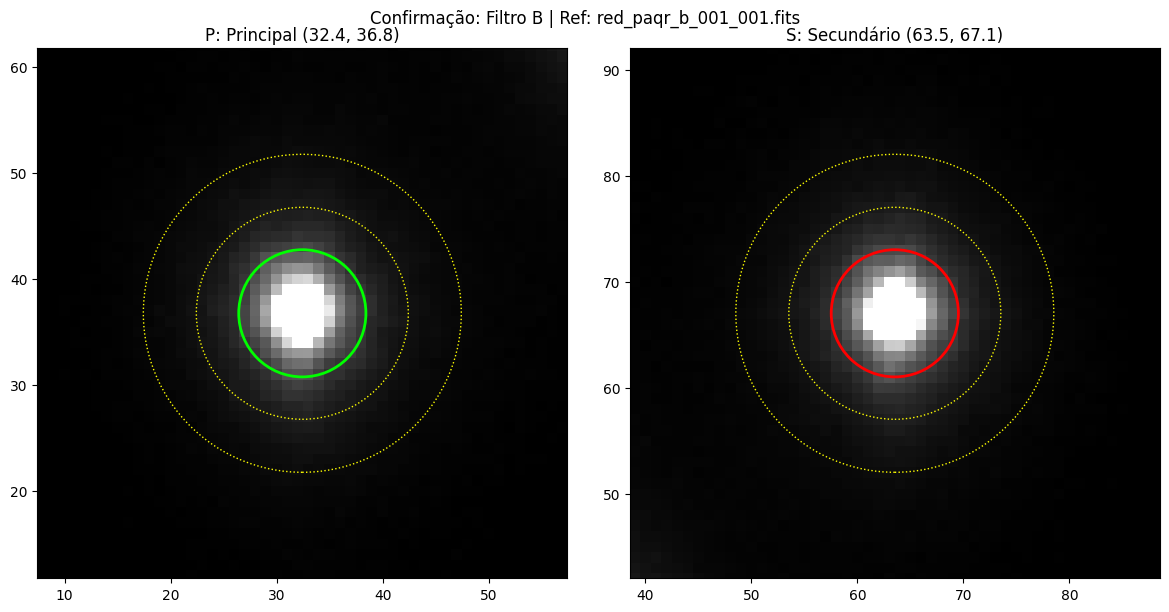

[1/800] red_paqr_b_001_001.fits | Pos 1 (0.0°) -> F_Prin=1068539 | F_Sec=1038299
[51/800] red_paqr_b_002_001.fits | Pos 2 (22.5°) -> F_Prin=1131187 | F_Sec=1080415
[101/800] red_paqr_b_003_001.fits | Pos 3 (45.0°) -> F_Prin=1122577 | F_Sec=1064386
[151/800] red_paqr_b_004_001.fits | Pos 4 (67.5°) -> F_Prin=1126399 | F_Sec=1085824
[201/800] red_paqr_b_005_001.fits | Pos 5 (90.0°) -> F_Prin=1119573 | F_Sec=1081693
[251/800] red_paqr_b_006_001.fits | Pos 6 (112.5°) -> F_Prin=1124898 | F_Sec=1073658
[301/800] red_paqr_b_007_001.fits | Pos 7 (135.0°) -> F_Prin=1115383 | F_Sec=1065722
[351/800] red_paqr_b_008_001.fits | Pos 8 (157.5°) -> F_Prin=1113973 | F_Sec=1078746
[401/800] red_paqr_b_009_001.fits | Pos 9 (180.0°) -> F_Prin=1119005 | F_Sec=1085272
[451/800] red_paqr_b_010_001.fits | Pos 10 (202.5°) -> F_Prin=259512 | F_Sec=1075062
[501/800] red_paqr_b_011_001.fits | Pos 11 (225.0°) -> F_Prin=1088143 | F_Sec=1046168
[551/800] red_paqr_b_012_001.fits | Pos 12 (247.5°) -> F_Prin=1098599 | F

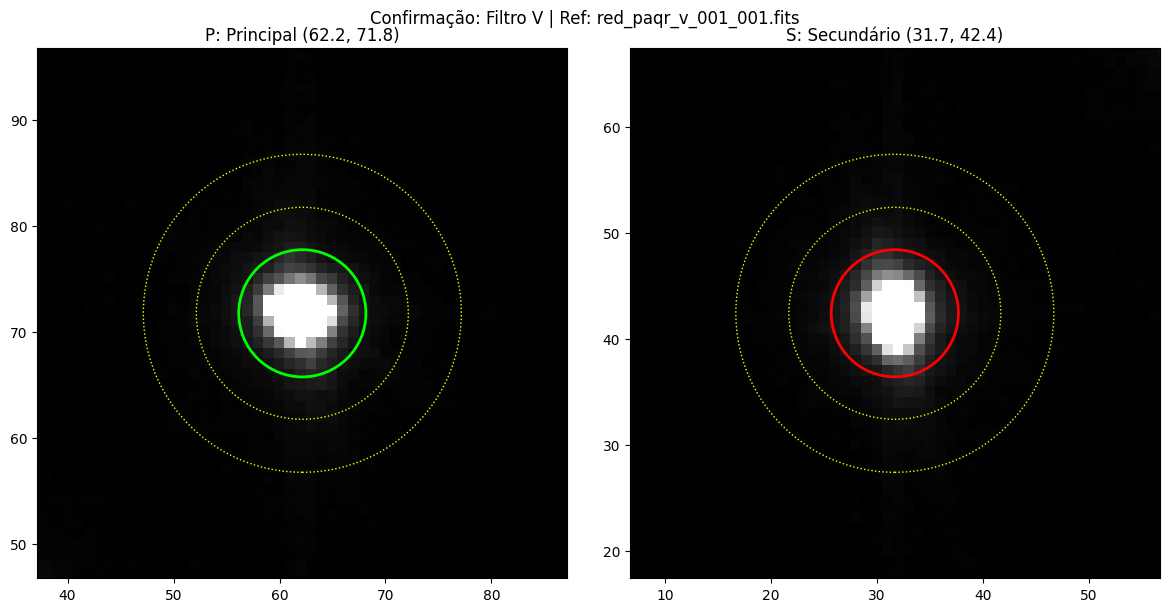

[1/800] red_paqr_v_001_001.fits | Pos 1 (0.0°) -> F_Prin=811979 | F_Sec=810623

⚠️  [ALERTA NA IMAGEM 12/800] red_paqr_v_001_012.fits
   Motivo: Queda de Sinal (>50% NUVEM/PERDA)


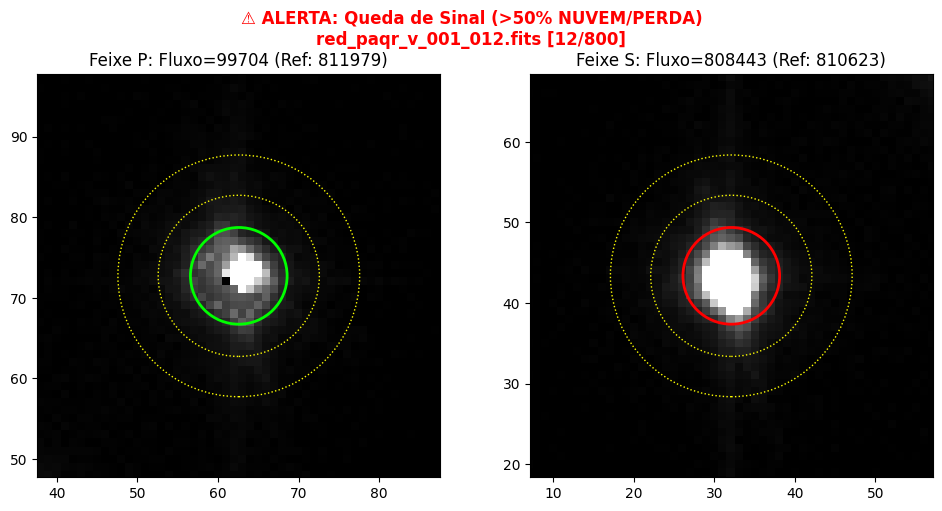

Opções de ação:
 [ENTER/S] Aceitar e Continuar
 [R]       Recalibrar Posição Âncora (se a estrela mudou de lugar)
 [M]       Mudar Referência de Fluxo (se o céu escureceu/mudou transparência)
 [C]       Continuar sem mais alertas neste filtro
-> Alertas desativados para o restante deste filtro. Processando no máximo...
[51/800] red_paqr_v_002_001.fits | Pos 2 (22.5°) -> F_Prin=152827 | F_Sec=817992
[101/800] red_paqr_v_003_001.fits | Pos 3 (45.0°) -> F_Prin=109097 | F_Sec=793301
[151/800] red_paqr_v_004_001.fits | Pos 4 (67.5°) -> F_Prin=799217 | F_Sec=209661
[201/800] red_paqr_v_005_001.fits | Pos 5 (90.0°) -> F_Prin=819478 | F_Sec=814523
[251/800] red_paqr_v_006_001.fits | Pos 6 (112.5°) -> F_Prin=792956 | F_Sec=799807
[301/800] red_paqr_v_007_001.fits | Pos 7 (135.0°) -> F_Prin=803867 | F_Sec=812630
[351/800] red_paqr_v_008_001.fits | Pos 8 (157.5°) -> F_Prin=821757 | F_Sec=816778
[401/800] red_paqr_v_009_001.fits | Pos 9 (180.0°) -> F_Prin=810252 | F_Sec=808872
[451/800] red_paqr_v

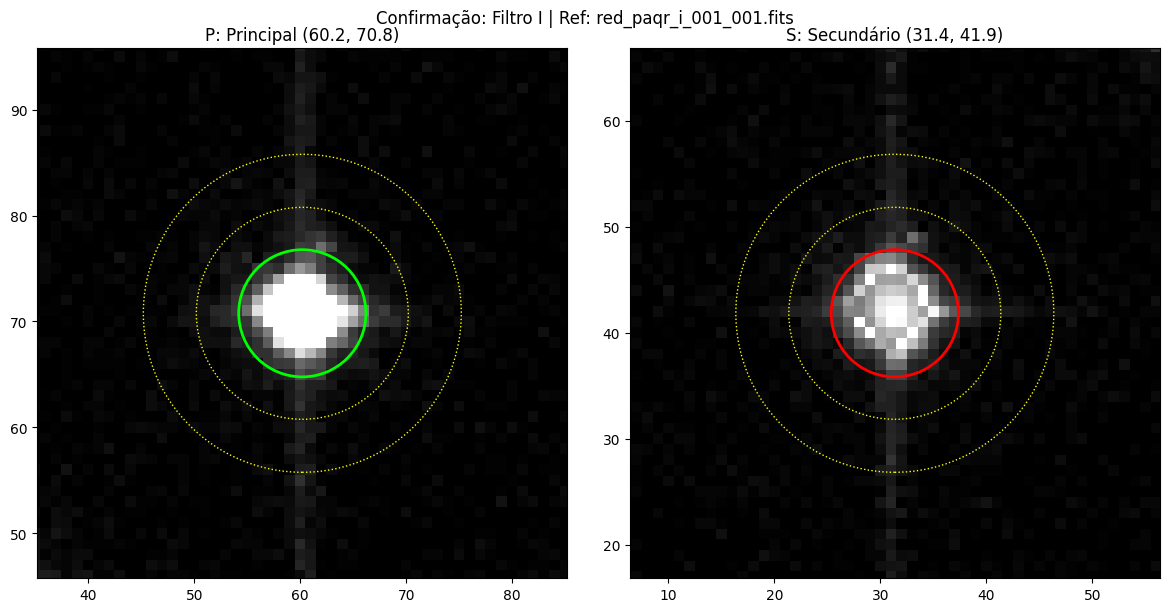

[1/800] red_paqr_i_001_001.fits | Pos 1 (0.0°) -> F_Prin=307045 | F_Sec=21354

⚠️  [ALERTA NA IMAGEM 4/800] red_paqr_i_001_004.fits
   Motivo: Queda de Sinal (>50% NUVEM/PERDA)


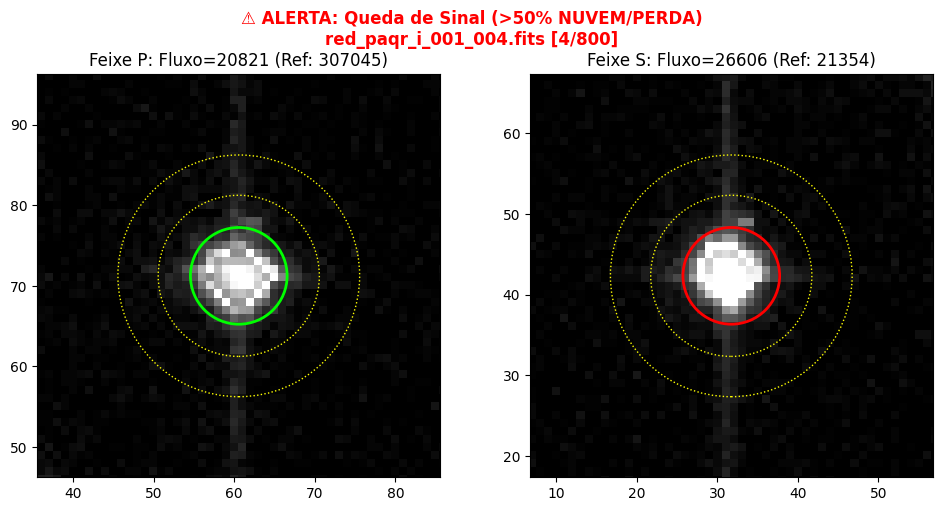

Opções de ação:
 [ENTER/S] Aceitar e Continuar
 [R]       Recalibrar Posição Âncora (se a estrela mudou de lugar)
 [M]       Mudar Referência de Fluxo (se o céu escureceu/mudou transparência)
 [C]       Continuar sem mais alertas neste filtro
-> Alertas desativados para o restante deste filtro. Processando no máximo...
[51/800] red_paqr_i_002_001.fits | Pos 2 (22.5°) -> F_Prin=22414 | F_Sec=22284
[101/800] red_paqr_i_003_001.fits | Pos 3 (45.0°) -> F_Prin=41978 | F_Sec=26850
[151/800] red_paqr_i_004_001.fits | Pos 4 (67.5°) -> F_Prin=25267 | F_Sec=36029
[201/800] red_paqr_i_005_001.fits | Pos 5 (90.0°) -> F_Prin=27411 | F_Sec=306091
[251/800] red_paqr_i_006_001.fits | Pos 6 (112.5°) -> F_Prin=305881 | F_Sec=22510
[301/800] red_paqr_i_007_001.fits | Pos 7 (135.0°) -> F_Prin=38622 | F_Sec=23124
[351/800] red_paqr_i_008_001.fits | Pos 8 (157.5°) -> F_Prin=37032 | F_Sec=30275
[401/800] red_paqr_i_009_001.fits | Pos 9 (180.0°) -> F_Prin=33562 | F_Sec=25684
[451/800] red_paqr_i_010_001.fits 

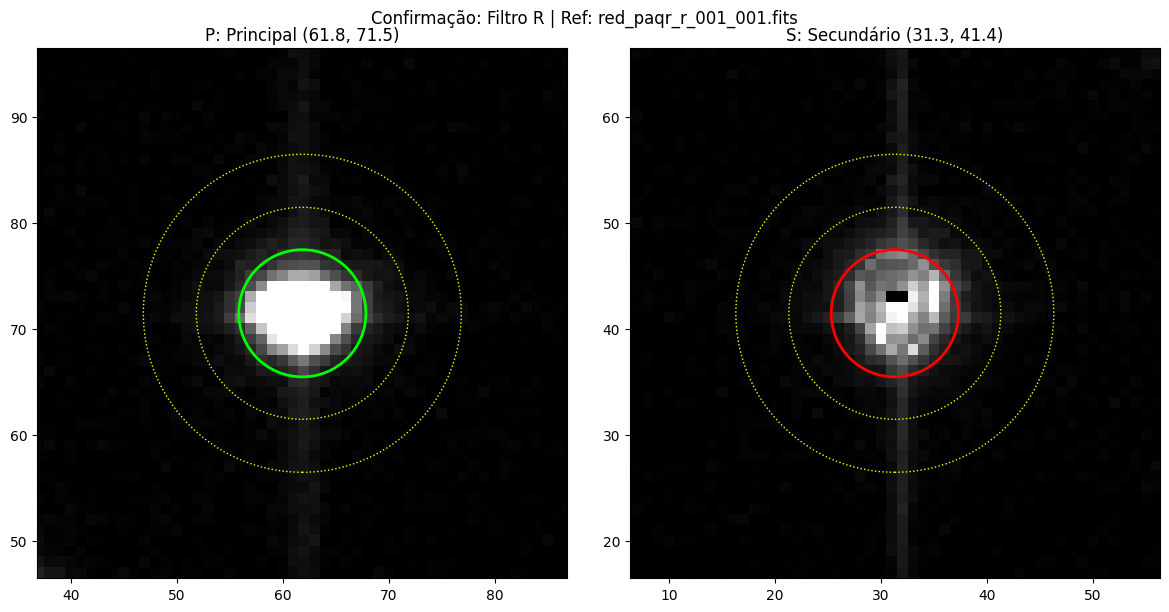

[1/800] red_paqr_r_001_001.fits | Pos 1 (0.0°) -> F_Prin=605959 | F_Sec=39784

⚠️  [ALERTA NA IMAGEM 6/800] red_paqr_r_001_006.fits
   Motivo: Queda de Sinal (>50% NUVEM/PERDA)


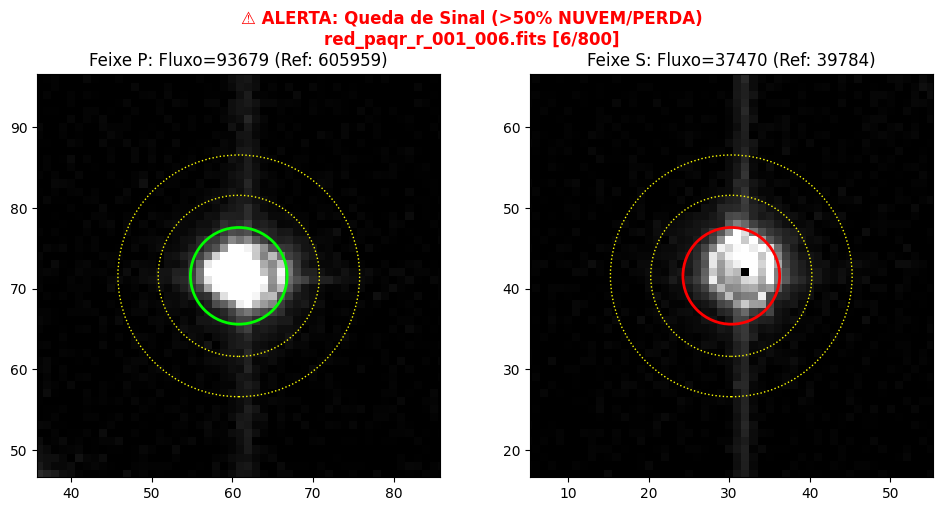

Opções de ação:
 [ENTER/S] Aceitar e Continuar
 [R]       Recalibrar Posição Âncora (se a estrela mudou de lugar)
 [M]       Mudar Referência de Fluxo (se o céu escureceu/mudou transparência)
 [C]       Continuar sem mais alertas neste filtro
-> Alertas desativados para o restante deste filtro. Processando no máximo...
[51/800] red_paqr_r_002_001.fits | Pos 2 (22.5°) -> F_Prin=590238 | F_Sec=592803
[101/800] red_paqr_r_003_001.fits | Pos 3 (45.0°) -> F_Prin=589482 | F_Sec=593469
[151/800] red_paqr_r_004_001.fits | Pos 4 (67.5°) -> F_Prin=83645 | F_Sec=93628
[201/800] red_paqr_r_005_001.fits | Pos 5 (90.0°) -> F_Prin=601594 | F_Sec=594672
[251/800] red_paqr_r_006_001.fits | Pos 6 (112.5°) -> F_Prin=593795 | F_Sec=50636
[301/800] red_paqr_r_007_001.fits | Pos 7 (135.0°) -> F_Prin=603990 | F_Sec=42909
[351/800] red_paqr_r_008_001.fits | Pos 8 (157.5°) -> F_Prin=610071 | F_Sec=41613
[401/800] red_paqr_r_009_001.fits | Pos 9 (180.0°) -> F_Prin=595247 | F_Sec=587708
[451/800] red_paqr_r_010_

In [64]:
#Loop por Filtro
for filtro, arquivos in arquivos_por_filtro.items():
    arquivos = sorted(arquivos)
    total_arq = len(arquivos)
    
    print(f"\n{'='*60}")
    print(f"PROCESSANDO FILTRO: '{filtro.upper()}' ({total_arq} imagens)")
    print(f"{'='*60}")
    
    imagem_referencia = arquivos[0]
    data_ref = fits.getdata(imagem_referencia)
    data_ref = np.squeeze(data_ref)
    data_ref = np.nan_to_num(data_ref, nan=np.nanmedian(data_ref), posinf=0, neginf=0)

    mean, median, std = sigma_clipped_stats(data_ref, sigma=3.0)
    bkg, rms = median, std

    daofind = DAOStarFinder(
    fwhm=3.0, 
    threshold=3.0 * rms, 
    sharplo=0.0, 
    sharphi=2.0, 
    roundlo=-2.0, 
    roundhi=2.0
)
    sources = daofind(data_ref - bkg)

    x = np.array(sources["xcentroid"] if "xcentroid" in sources.colnames else sources["x_centroid"])
    y = np.array(sources["ycentroid"] if "ycentroid" in sources.colnames else sources["y_centroid"])
    fluxo = np.array(sources["flux"])

    idx_principal = np.argmax(fluxo)
    x_prin_ref, y_prin_ref = x[idx_principal], y[idx_principal]

    raio_busca = 41.0
    dr = 8.0
    distancias = np.sqrt((x - x_prin_ref)**2 + (y - y_prin_ref)**2)
    mascara_anel = (distancias >= (raio_busca - dr)) & (distancias <= (raio_busca + dr)) & (distancias > 0.1)
    indices_secundarios = np.where(mascara_anel)[0]

    if len(indices_secundarios) > 0:
        fluxos_no_anel = fluxo[indices_secundarios]
        idx_sec = indices_secundarios[np.argmax(fluxos_no_anel)]
        x_sec_ref, y_sec_ref = x[idx_sec], y[idx_sec]
    else:
        print(f"[ERRO] Deteção radial falhou no filtro {filtro.upper()}. Pulando...")
        continue

    dx_rigido = x_sec_ref - x_prin_ref
    dy_rigido = y_sec_ref - y_prin_ref

    # --- Verificação humana ---
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))
    fig.suptitle(f"Confirmação: Filtro {filtro.upper()} | Ref: {os.path.basename(imagem_referencia)}")

    vmin = np.median(data_ref)
    vmax = np.percentile(data_ref, 99.5)

    ax1.imshow(data_ref, cmap="gray", origin="lower", vmin=vmin, vmax=vmax)
    ax1.set_title(f"P: Principal ({x_prin_ref:.1f}, {y_prin_ref:.1f})")
    ax1.add_patch(Circle((x_prin_ref, y_prin_ref), raio_abertura, color='lime', fill=False, lw=2))
    ax1.add_patch(Circle((x_prin_ref, y_prin_ref), r_in_sky, color='yellow', fill=False, ls=':'))
    ax1.add_patch(Circle((x_prin_ref, y_prin_ref), r_out_sky, color='yellow', fill=False, ls=':'))
    ax1.set_xlim(x_prin_ref - 25, x_prin_ref + 25)
    ax1.set_ylim(y_prin_ref - 25, y_prin_ref + 25)

    ax2.imshow(data_ref, cmap="gray", origin="lower", vmin=vmin, vmax=vmax)
    ax2.set_title(f"S: Secundário ({x_sec_ref:.1f}, {y_sec_ref:.1f})")
    ax2.add_patch(Circle((x_sec_ref, y_sec_ref), raio_abertura, color='red', fill=False, lw=2))
    ax2.add_patch(Circle((x_sec_ref, y_sec_ref), r_in_sky, color='yellow', fill=False, ls=':'))
    ax2.add_patch(Circle((x_sec_ref, y_sec_ref), r_out_sky, color='yellow', fill=False, ls=':'))
    ax2.set_xlim(x_sec_ref - 25, x_sec_ref + 25)
    ax2.set_ylim(y_sec_ref - 25, y_sec_ref + 25)

    plt.tight_layout()
    plt.show()

    confirma = input(f"Filtro {filtro.upper()}: As estrelas e anéis de céu estão corretos? (S/N): ").upper()
    if confirma != 'S' and confirma != '':
        continue

    # --- EXTRAÇÃO COM SUBTRAÇÃO DE CÉU E VÍNCULO RÍGIDO ---(GEMINI)
    arquivo_saida = os.path.join(pasta_reduced_estrela, f'fotometria_filtro_{filtro}.csv')

    with open(arquivo_saida, 'w') as f_out:
        f_out.write("Arquivo,Posicao,Angulo,X_Prin,Y_Prin,Fluxo_Prin,X_Sec,Y_Sec,Fluxo_Sec\n")
        
        # Variáveis de referência para o Alerta Inteligente (inicializadas com a 1ª imagem)
        fluxo_p_ref = None
        fluxo_s_ref = None
        ignorar_alertas = False # Permite ao operador desativar alertas se a noite estiver muito instável

        for i, arq in enumerate(arquivos):
            nome = os.path.basename(arq)
            partes = nome.split('_')
            try:
                posicao_int = int(partes[3])
                angulo_psi = (posicao_int - 1) * 22.5
            except (IndexError, ValueError):
                posicao_int = 0
                angulo_psi = 0.0
            
            dados = fits.getdata(arq)
            dados = np.squeeze(dados)
            dados = np.nan_to_num(dados, nan=np.nanmedian(dados), posinf=0, neginf=0)
            
            # 1. Rastreia o feixe principal ancorado na referência
            x_prin, y_prin = rastrear_centroide_ancorado(dados, x_prin_ref, y_prin_ref, janela=janela_busca)
            
            # 2. Vínculo rígido do feixe secundário (Calcita IAGpol)
            x_sec = x_prin + dx_rigido
            y_sec = y_prin + dy_rigido
            
            # 3. Fotometria com Anel de Céu
            aper_p = CircularAperture((x_prin, y_prin), r=raio_abertura)
            ann_p = CircularAnnulus((x_prin, y_prin), r_in=r_in_sky, r_out=r_out_sky)
            phot_p = aperture_photometry(dados, [aper_p, ann_p])
            
            aper_s = CircularAperture((x_sec, y_sec), r=raio_abertura)
            ann_s = CircularAnnulus((x_sec, y_sec), r_in=r_in_sky, r_out=r_out_sky)
            phot_s = aperture_photometry(dados, [aper_s, ann_s])
            
            bkg_p_pixel = phot_p['aperture_sum_1'][0] / area_ann
            fluxo_p = phot_p['aperture_sum_0'][0] - (bkg_p_pixel * area_aper)
            
            bkg_s_pixel = phot_s['aperture_sum_1'][0] / area_ann
            fluxo_s = phot_s['aperture_sum_0'][0] - (bkg_s_pixel * area_aper)
            
            # Guarda o fluxo da 1ª imagem como referência do brilho esperado da estrela
            if i == 0:
                fluxo_p_ref = max(fluxo_p, 100.0)
                fluxo_s_ref = max(fluxo_s, 100.0)

            # --- LÓGICA DO ALERTA INTELIGENTE ---
            desvio_posicao = np.sqrt((x_prin - x_prin_ref)**2 + (y_prin - y_prin_ref)**2)
            queda_fluxo_p = fluxo_p < (0.50 * fluxo_p_ref) # Perdeu mais de 50% do brilho
            queda_fluxo_s = fluxo_s < (0.50 * fluxo_s_ref)
            # Dispara o alerta APENAS se o fluxo cair mais de 80% (nuvem densa) ou se a estrela sair da janela (> 8.0 px)
            queda_critica = (fluxo_p < 0.20 * fluxo_p_ref) or (fluxo_s < 0.20 * fluxo_s_ref)
            deslocado_critico = desvio_posicao > 8.0

            ha_anomalia = (queda_critica or deslocado_critico)

            if ha_anomalia and not ignorar_alertas:
                # Identifica o motivo do alerta para mostrar no terminal
                motivos = []
                if deslocado_critico: motivos.append(f"Pulo de Posição ({desvio_posicao:.1f}px)")
                if queda_fluxo_p or queda_fluxo_s: motivos.append("Queda de Sinal (>50% NUVEM/PERDA)")
                motivo_str = " | ".join(motivos)
                
                print(f"\n⚠️  [ALERTA NA IMAGEM {i+1}/{total_arq}] {nome}")
                print(f"   Motivo: {motivo_str}")
                
                fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))
                fig.suptitle(f"⚠️ ALERTA: {motivo_str}\n{nome} [{i+1}/{total_arq}]", color='red', fontweight='bold')
                
                vmin = np.median(dados)
                vmax = np.percentile(dados, 99.5)
                
                # Zoom Principal
                ax1.imshow(dados, cmap="gray", origin="lower", vmin=vmin, vmax=vmax)
                ax1.add_patch(Circle((x_prin, y_prin), raio_abertura, color='lime', fill=False, lw=2))
                ax1.add_patch(Circle((x_prin, y_prin), r_in_sky, color='yellow', fill=False, ls=':'))
                ax1.add_patch(Circle((x_prin, y_prin), r_out_sky, color='yellow', fill=False, ls=':'))
                ax1.set_xlim(x_prin - 25, x_prin + 25)
                ax1.set_ylim(y_prin - 25, y_prin + 25)
                ax1.set_title(f"Feixe P: Fluxo={fluxo_p:.0f} (Ref: {fluxo_p_ref:.0f})")
                
                # Zoom Secundário
                ax2.imshow(dados, cmap="gray", origin="lower", vmin=vmin, vmax=vmax)
                ax2.add_patch(Circle((x_sec, y_sec), raio_abertura, color='red', fill=False, lw=2))
                ax2.add_patch(Circle((x_sec, y_sec), r_in_sky, color='yellow', fill=False, ls=':'))
                ax2.add_patch(Circle((x_sec, y_sec), r_out_sky, color='yellow', fill=False, ls=':'))
                ax2.set_xlim(x_sec - 25, x_sec + 25)
                ax2.set_ylim(y_sec - 25, y_sec + 25)
                ax2.set_title(f"Feixe S: Fluxo={fluxo_s:.0f} (Ref: {fluxo_s_ref:.0f})")
                
                plt.tight_layout()
                plt.show()
                
                print("Opções de ação:")
                print(" [ENTER/S] Aceitar e Continuar")
                print(" [R]       Recalibrar Posição Âncora (se a estrela mudou de lugar)")
                print(" [M]       Mudar Referência de Fluxo (se o céu escureceu/mudou transparência)")
                print(" [C]       Continuar sem mais alertas neste filtro")
                
                resp = input("Escolha uma opção (ENTER/S/R/M/C): ").upper().strip()
                
                if resp == 'R':
                    x_prin_ref = float(input(f"Novo X âncora (Atual: {x_prin:.1f}): "))
                    y_prin_ref = float(input(f"Novo Y âncora (Atual: {y_prin:.1f}): "))
                    x_prin, y_prin = rastrear_centroide_ancorado(dados, x_prin_ref, y_prin_ref, janela=janela_busca)
                    x_sec = x_prin + dx_rigido
                    y_sec = y_prin + dy_rigido
                elif resp == 'M':
                    fluxo_p_ref = max(fluxo_p, 100.0)
                    fluxo_s_ref = max(fluxo_s, 100.0)
                    print("-> Novo nível de brilho de referência atualizado!")
                elif resp == 'C':
                    ignorar_alertas = True
                    print("-> Alertas desativados para o restante deste filtro. Processando no máximo...")

            # Exibe progresso silencioso no terminal a cada 50 imagens
            if i % 50 == 0 or i == total_arq - 1:
                print(f"[{i+1}/{total_arq}] {nome} | Pos {posicao_int} ({angulo_psi}°) -> F_Prin={fluxo_p:.0f} | F_Sec={fluxo_s:.0f}")
            
            f_out.write(f"{nome},{posicao_int},{angulo_psi:.1f},{x_prin:.3f},{y_prin:.3f},{fluxo_p:.3f},{x_sec:.3f},{y_sec:.3f},{fluxo_s:.3f}\n")

    print(f"✅ Filtro {filtro.upper()} finalizado e salvo em {arquivo_saida}!")

print("\n=== RE-EXTRAÇÃO CONCLUÍDA COM SUCESSO! ===")

# **Dados Finais 1**

In [65]:
#Ajustes para o final
arquivos_csv = sorted(glob.glob(os.path.join(pasta_reduced_estrela, 'fotometria_filtro_*.csv')))

if not arquivos_csv:
    raise FileNotFoundError("Nenhum arquivo CSV de fotometria foi encontrado.")

# Solver de Mínimos Quadrados do astropop para lâmina de meia-onda
pol_solver = SLSDualBeamPolarimetry('halfwave', compute_k=True)

resultados_finais = []

2026-10-13 18:13:02,319 astropop - INFO - Errors will not be considered in the fit.  [__init__]
2026-10-13 18:13:02,327 astropop - INFO - Errors will not be considered in the fit.  [__init__]


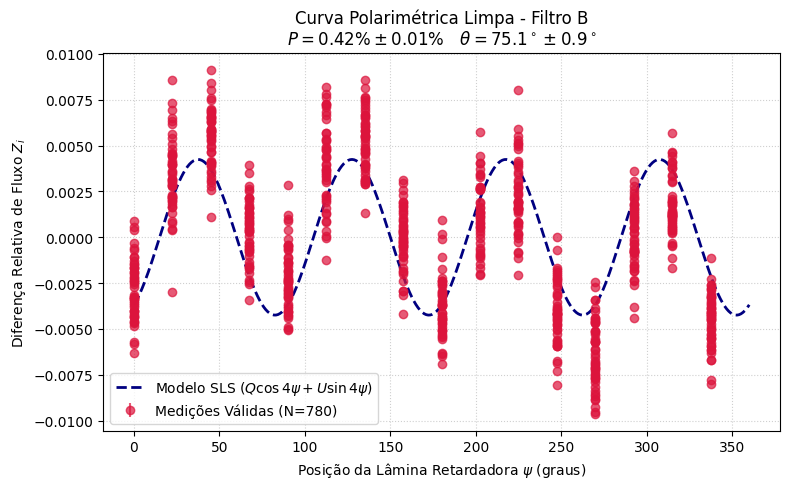

2026-10-13 18:13:02,515 astropop - INFO - Errors will not be considered in the fit.  [__init__]
2026-10-13 18:13:02,520 astropop - INFO - Errors will not be considered in the fit.  [__init__]


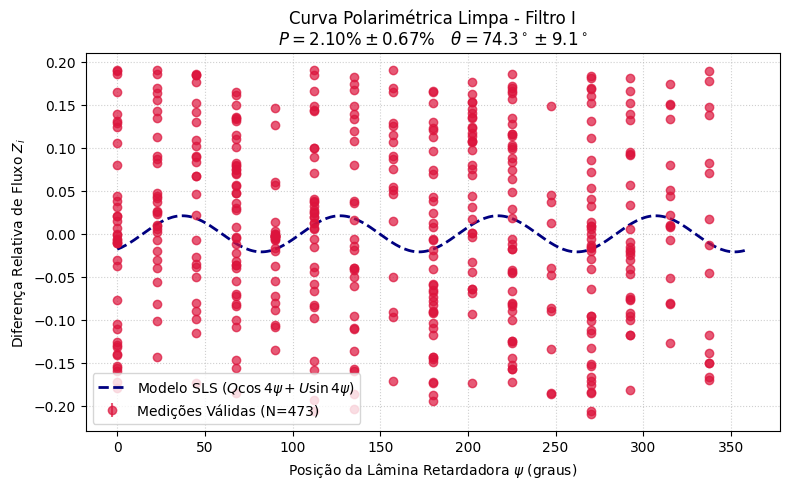

2026-10-13 18:13:02,710 astropop - INFO - Errors will not be considered in the fit.  [__init__]
2026-10-13 18:13:02,714 astropop - INFO - Errors will not be considered in the fit.  [__init__]


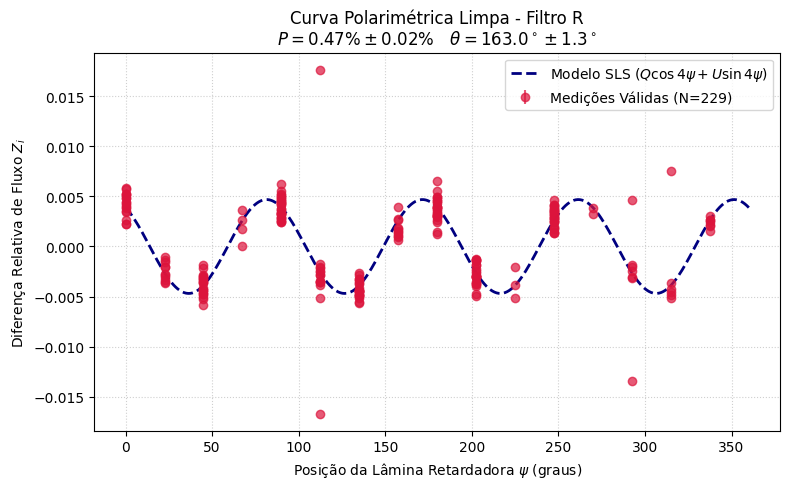

2026-10-13 18:13:02,861 astropop - INFO - Errors will not be considered in the fit.  [__init__]
2026-10-13 18:13:02,872 astropop - INFO - Errors will not be considered in the fit.  [__init__]


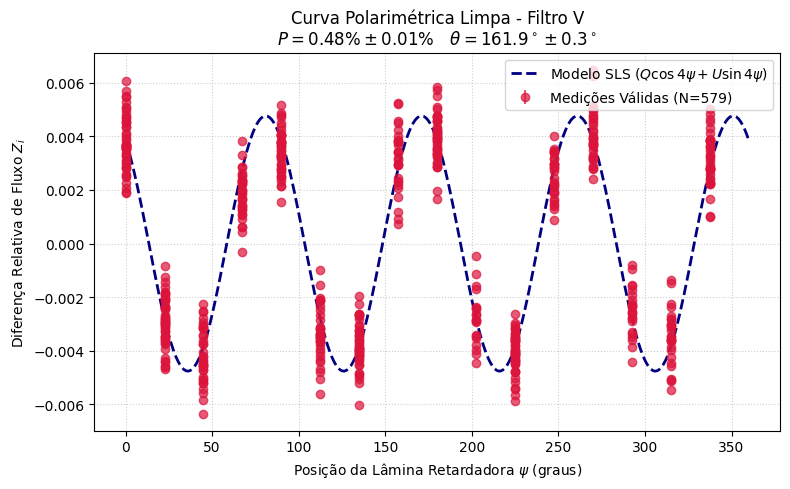


  RESUMO DA POLARIMETRIA FINAL (TODOS OS FILTROS)
Filtro N_Usados         P (%)     Theta (°)      k      RMS
     B  780/800 0.425 ± 0.013  75.09 ± 0.86 1.0387 0.002512
     I  473/800 2.099 ± 0.668  74.30 ± 9.11 1.0196 0.104011
     R  229/800 0.469 ± 0.021 162.97 ± 1.26 1.0028 0.002234
     V  579/800 0.476 ± 0.006 161.92 ± 0.34 0.9957 0.000976


In [66]:
# Resumo final em tabela no terminal
for csv_file in arquivos_csv:
    filtro = os.path.basename(csv_file).split('_')[-1].replace('.csv', '').upper()
    df = pd.read_csv(csv_file)
    
    # 1. Filtra quadros com contaminação severa/fluxos inválidos
    df_valido = df[(df['Fluxo_Prin'] > 100) & (df['Fluxo_Sec'] > 100)].copy()
    
    # 2. Descarte primário de dispersões grotescas (|Zi| >= 0.20)
    df_valido['Zi_raw'] = (df_valido['Fluxo_Sec'] - df_valido['Fluxo_Prin']) / (df_valido['Fluxo_Sec'] + df_valido['Fluxo_Prin'])
    df_limpo = df_valido[np.abs(df_valido['Zi_raw']) < 0.20].copy()
    
    if len(df_limpo) == 0:
        print(f"[{filtro}] Nenhum dado válido restou após filtros primários.")
        continue

    psi = df_limpo['Angulo'].values
    fo = df_limpo['Fluxo_Prin'].values
    fe = df_limpo['Fluxo_Sec'].values
    
    # 3. Ajuste preliminar no astropop
    res_preliminar = pol_solver.compute(psi, fo, fe)
    
    # 4. Rejeição refinada por 3-Sigma nos resíduos do modelo
    residuos = res_preliminar.zi.nominal - res_preliminar.model(psi * u.deg).nominal
    mascara_boa = ~sigma_clip(residuos, sigma=3.0).mask
    
    # 5. Ajuste Final de Mínimos Quadrados
    resultado_final = pol_solver.compute(psi[mascara_boa], fo[mascara_boa], fe[mascara_boa])
    
    n_total = len(df)
    n_usados = np.sum(mascara_boa)
    
    p_pct = resultado_final.p.nominal * 100
    p_err = resultado_final.p.std_dev * 100
    theta_deg = resultado_final.theta.nominal
    theta_err = resultado_final.theta.std_dev
    
    resultados_finais.append({
        'Filtro': filtro,
        'N_Usados': f"{n_usados}/{n_total}",
        'P (%)': f"{p_pct:.3f} ± {p_err:.3f}",
        'Theta (°)': f"{theta_deg:.2f} ± {theta_err:.2f}",
        'k': f"{resultado_final.k:.4f}",
        'RMS': f"{resultado_final.rms:.6f}"
    })
    
    # 6. Plotagem da Curva de Modulação
    plt.figure(figsize=(8, 5))
    
    plt.errorbar(resultado_final.psi.nominal, resultado_final.zi.nominal, 
                 yerr=resultado_final.zi.std_dev, fmt='o', color='crimson', 
                 alpha=0.7, label=f'Medições Válidas (N={n_usados})')
    
    eixo_psi = np.linspace(0, 360, 300)
    modelo_zi = resultado_final.model(eixo_psi * u.deg).nominal
    plt.plot(eixo_psi, modelo_zi, '--', color='navy', lw=2, label='Modelo SLS ($Q\cos 4\psi + U\sin 4\psi$)')
    
    plt.title(f"Curva Polarimétrica Limpa - Filtro {filtro}\n$P = {p_pct:.2f}\% \pm {p_err:.2f}\% \quad \\theta = {theta_deg:.1f}^\circ \pm {theta_err:.1f}^\circ$")
    plt.xlabel(r"Posição da Lâmina Retardadora $\psi$ (graus)")
    plt.ylabel(r"Diferença Relativa de Fluxo $Z_i$")
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.legend(loc='best')
    plt.tight_layout()
    plt.show()

# Resumo final em tabela no terminal
print("\n" + "="*70)
print("  RESUMO DA POLARIMETRIA FINAL (TODOS OS FILTROS)")
print("="*70)
df_resumo = pd.DataFrame(resultados_finais)
print(df_resumo.to_string(index=False))